<a href="https://colab.research.google.com/github/aeron-j/G12-Flood-Aware-Dynamic-Delivery-Routing-via-Vision-Transformers/blob/main/flood_vit_classifier.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip -q install -U keras-hub
import tensorflow as tf, keras, keras_hub
print('GPU:', tf.config.list_physical_devices('GPU'))

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
keras-nlp 0.26.0 requires keras-hub==0.26.0, but you have keras-hub 0.33.0 which is incompatible.
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
from pathlib import Path

DATA_DIR = Path('/content/drive/MyDrive/Sorted_Dataset')
CLASSES = ['clear', 'passable', 'impassable']
IMG_EXT = {'.jpg', '.jpeg', '.png', '.webp'}

for c in CLASSES:
    files = [p for p in (DATA_DIR / c).glob('*') if p.suffix.lower() in IMG_EXT]
    print(c, len(files))

clear 111
passable 115
impassable 326


## **Step 4: Inspect Data then Split**

clear | sample names: ['clean_1.jpg', 'clean_100.jpg', 'clean_101.jpg', 'clean_102.jpg']
   median size: 956 x 614
passable | sample names: ['image_1.jpg', 'image_116.jpg', 'image_122.jpg', 'image_130.jpg']
   median size: 512 x 384
impassable | sample names: ['image_10.jpg', 'image_100.jpg', 'image_101.jpg', 'image_102.jpg']
   median size: 512 x 384


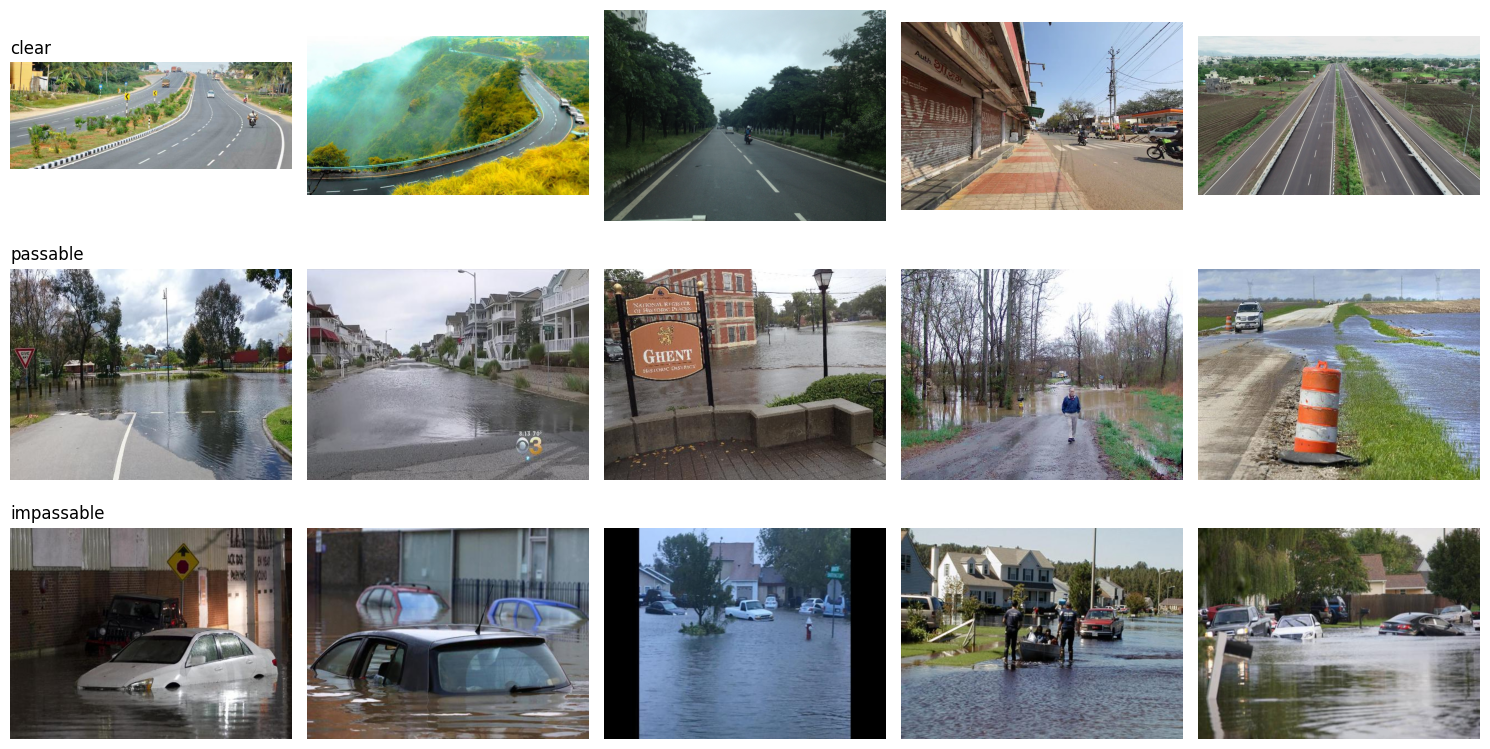

In [4]:
import random
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

random.seed(0)
for c in CLASSES:
    files = [p for p in (DATA_DIR / c).glob('*') if p.suffix.lower() in IMG_EXT]
    print(c, '| sample names:', sorted(p.name for p in files)[:4])
    sizes = [Image.open(p).size for p in random.sample(files, min(30, len(files)))]
    print(f"   median size: {np.median([s[0] for s in sizes]):.0f} x {np.median([s[1] for s in sizes]):.0f}")

fig, axes = plt.subplots(3, 5, figsize=(15, 8))
for r, c in enumerate(CLASSES):
    files = [p for p in (DATA_DIR / c).glob('*') if p.suffix.lower() in IMG_EXT]
    for ax, p in zip(axes[r], random.sample(files, 5)):
        ax.imshow(Image.open(p).convert('RGB')); ax.axis('off')
    axes[r][0].set_title(c, loc='left')
plt.tight_layout(); plt.show()

In [5]:
import pandas as pd
from sklearn.model_selection import StratifiedGroupKFold

SEED = 42
rows = []
for label, c in enumerate(CLASSES):
    for p in sorted((DATA_DIR / c).glob('*')):
        if p.suffix.lower() in IMG_EXT:
            rows.append(dict(path=str(p), name=p.name, label=label, cls=c))
df = pd.DataFrame(rows)

def get_group(name):
    stem = name.rsplit('.', 1)[0]
    return stem.split('__')[0] if '__' in stem else stem   # edit this if your filenames use another pattern

df['group'] = df.name.map(get_group)
print(df.group.nunique(), 'source groups for', len(df), 'images')

df['split'] = 'train'
sg = StratifiedGroupKFold(n_splits=7, shuffle=True, random_state=SEED)
tv_idx, te_idx = next(sg.split(df, df.label, df.group))
df.loc[te_idx, 'split'] = 'test'
tv = df.loc[tv_idx]
sg2 = StratifiedGroupKFold(n_splits=6, shuffle=True, random_state=SEED)
_, va_idx = next(sg2.split(tv, tv.label, tv.group))
df.loc[tv.index[va_idx], 'split'] = 'val'

g = {s: set(df[df.split == s].group) for s in ['train', 'val', 'test']}
assert not (g['train'] & g['val']) and not (g['train'] & g['test']) and not (g['val'] & g['test'])

OUT_DIR = Path('/content/drive/MyDrive/flood_project'); OUT_DIR.mkdir(exist_ok=True)
df[['name', 'cls', 'group', 'split']].to_csv(OUT_DIR / 'splits.csv', index=False)
print(pd.crosstab(df.split, df.cls).reindex(index=['train', 'val', 'test'], columns=CLASSES))

552 source groups for 552 images
cls    clear  passable  impassable
split                             
train     78        84         232
val       16        15          48
test      17        16          46


## **Step 5: Data Pipeline**

In [7]:
import shutil, numpy as np, tensorflow as tf, keras

# Copy to local disk (Drive is slow for many small files)
LOCAL = Path('/content/data')
if not LOCAL.exists():
    shutil.copytree(DATA_DIR, LOCAL)
df['path'] = df.apply(lambda r: str(LOCAL / r['cls'] / r['name']), axis=1)

IMG_SIZE, BATCH_SIZE = 224, 32
train_df = df[df.split == 'train'].reset_index(drop=True)
val_df = df[df.split == 'val'].reset_index(drop=True)   # test split deliberately not loaded

def load_image(path, label):
    img = tf.io.decode_image(tf.io.read_file(path), channels=3, expand_animations=False)
    img = tf.image.resize(img, (IMG_SIZE, IMG_SIZE))     # keeps 0-255 values; the model's preprocessor rescales
    return img, label

augment = keras.Sequential([
    keras.layers.RandomFlip('horizontal'),
    keras.layers.RandomZoom(0.15),
    keras.layers.RandomBrightness(0.2),
    keras.layers.RandomContrast(0.2),
])

def make_ds(frame, training):
    ds = tf.data.Dataset.from_tensor_slices((frame.path.values, frame.label.values))
    if training:
        ds = ds.shuffle(len(frame), seed=SEED)
    ds = ds.map(load_image, num_parallel_calls=tf.data.AUTOTUNE).batch(BATCH_SIZE)
    if training:
        ds = ds.map(lambda x, y: (augment(x, training=True), y), num_parallel_calls=tf.data.AUTOTUNE)
    return ds.prefetch(tf.data.AUTOTUNE)

train_ds, val_ds = make_ds(train_df, True), make_ds(val_df, False)

# Class weights so the rarer classes count more in the loss
counts = train_df.label.value_counts().sort_index().values
class_weight = {i: len(train_df) / (len(counts) * c) for i, c in enumerate(counts)}
print('class weights:', class_weight)

class weights: {0: np.float64(1.6837606837606838), 1: np.float64(1.5634920634920635), 2: np.float64(0.5660919540229885)}


## **Step 6: Build Model**

In [13]:
preset = 'vit_base_patch16_224_imagenet'
backbone = keras_hub.models.Backbone.from_preset(preset)
preprocessor = keras_hub.models.ViTImageClassifierPreprocessor.from_preset(preset)
model = keras_hub.models.ViTImageClassifier(backbone=backbone, num_classes=len(CLASSES), preprocessor=preprocessor)

model.compile(
    optimizer=keras.optimizers.AdamW(learning_rate=3e-5, weight_decay=0.05),
    loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=['accuracy'],
)

100%|██████████| 909/909 [00:00<00:00, 2.42MB/s]


## **Step 7: Train**

#### Version 1(baseline): class weights

In [9]:
history = model.fit(train_ds, validation_data=val_ds, epochs=8, class_weight=class_weight)
model.save_weights(OUT_DIR / 'vit_base.weights.h5')

Epoch 1/8


/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


13/13 ━━━━━━━━━━━━━━━━━━━━ 104s 4s/step - accuracy: 0.6726 - loss: 0.7461 - val_accuracy: 0.6709 - val_loss: 0.7192
Epoch 2/8
13/13 ━━━━━━━━━━━━━━━━━━━━ 17s 1s/step - accuracy: 0.8604 - loss: 0.2604 - val_accuracy: 0.8354 - val_loss: 0.4292
Epoch 3/8
13/13 ━━━━━━━━━━━━━━━━━━━━ 19s 1s/step - accuracy: 0.9289 - loss: 0.1348 - val_accuracy: 0.8734 - val_loss: 0.4091
Epoch 4/8
13/13 ━━━━━━━━━━━━━━━━━━━━ 21s 2s/step - accuracy: 0.9772 - loss: 0.0766 - val_accuracy: 0.8481 - val_loss: 0.3974
Epoch 5/8
13/13 ━━━━━━━━━━━━━━━━━━━━ 21s 2s/step - accuracy: 0.9848 - loss: 0.0513 - val_accuracy: 0.8354 - val_loss: 0.4102
Epoch 6/8
13/13 ━━━━━━━━━━━━━━━━━━━━ 40s 1s/step - accuracy: 0.9975 - loss: 0.0275 - val_accuracy: 0.8481 - val_loss: 0.4130
Epoch 7/8
13/13 ━━━━━━━━━━━━━━━━━━━━ 22s 2s/step - accuracy: 0.9949 - loss: 0.0233 - val_accuracy: 0.8481 - val_loss: 0.4011
Epoch 8/8
13/13 ━━━━━━━━━━━━━━━━━━━━ 20s 2s/step - accuracy: 0.9975 - loss: 0.0181 - val_accuracy: 0.8481 - val_loss: 0.4129


#### Version 2: softer class weights + early stopping

In [14]:
# v2: fresh pretrained model + softer class weights + early stopping
preset = 'vit_base_patch16_224_imagenet'
backbone = keras_hub.models.Backbone.from_preset(preset)
preprocessor = keras_hub.models.ViTImageClassifierPreprocessor.from_preset(preset)
model = keras_hub.models.ViTImageClassifier(backbone=backbone, num_classes=len(CLASSES), preprocessor=preprocessor)
model.compile(
    optimizer=keras.optimizers.AdamW(learning_rate=3e-5, weight_decay=0.05),
    loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=['accuracy'],
)

soft_weight = {i: w ** 0.5 for i, w in class_weight.items()}
early = keras.callbacks.EarlyStopping(monitor='val_loss', patience=2, restore_best_weights=True)
history = model.fit(train_ds, validation_data=val_ds, epochs=8, class_weight=soft_weight, callbacks=[early])
model.save_weights(OUT_DIR / 'vit_base_v2.weights.h5')

Epoch 1/8


/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


13/13 ━━━━━━━━━━━━━━━━━━━━ 91s 4s/step - accuracy: 0.5863 - loss: 0.9829 - val_accuracy: 0.7722 - val_loss: 0.6093
Epoch 2/8
13/13 ━━━━━━━━━━━━━━━━━━━━ 21s 2s/step - accuracy: 0.8807 - loss: 0.3222 - val_accuracy: 0.8481 - val_loss: 0.3546
Epoch 3/8
13/13 ━━━━━━━━━━━━━━━━━━━━ 42s 2s/step - accuracy: 0.9289 - loss: 0.1899 - val_accuracy: 0.8608 - val_loss: 0.3289
Epoch 4/8
13/13 ━━━━━━━━━━━━━━━━━━━━ 20s 1s/step - accuracy: 0.9645 - loss: 0.1013 - val_accuracy: 0.8608 - val_loss: 0.3541
Epoch 5/8
13/13 ━━━━━━━━━━━━━━━━━━━━ 19s 1s/step - accuracy: 0.9772 - loss: 0.0726 - val_accuracy: 0.8608 - val_loss: 0.3138
Epoch 6/8
13/13 ━━━━━━━━━━━━━━━━━━━━ 19s 1s/step - accuracy: 0.9924 - loss: 0.0452 - val_accuracy: 0.8608 - val_loss: 0.3215
Epoch 7/8
13/13 ━━━━━━━━━━━━━━━━━━━━ 19s 1s/step - accuracy: 0.9975 - loss: 0.0282 - val_accuracy: 0.8734 - val_loss: 0.3185


## **Step 8: Evaluation**

3/3 ━━━━━━━━━━━━━━━━━━━━ 10s 3s/step
              precision    recall  f1-score   support

       clear      0.889     1.000     0.941        16
    passable      0.667     0.533     0.593        15
  impassable      0.898     0.917     0.907        48

    accuracy                          0.861        79
   macro avg      0.818     0.817     0.814        79
weighted avg      0.852     0.861     0.854        79

macro-F1: 0.814


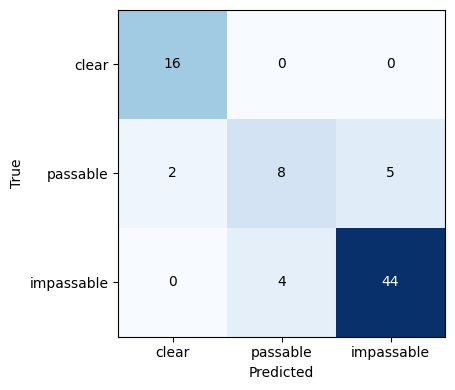

impassable called clear: 0.0%
impassable missed (called clear or passable): 8.3%


In [15]:
from sklearn.metrics import classification_report, confusion_matrix, f1_score

val_eval_ds = make_ds(val_df, False)          # same order as val_df
logits = model.predict(val_eval_ds)
probs = tf.nn.softmax(logits, axis=-1).numpy()
preds = probs.argmax(1)
ys = val_df.label.values

print(classification_report(ys, preds, target_names=CLASSES, digits=3))
print('macro-F1:', round(f1_score(ys, preds, average='macro'), 3))

cm = confusion_matrix(ys, preds)
fig, ax = plt.subplots(figsize=(5, 4)); ax.imshow(cm, cmap='Blues')
ax.set_xticks(range(3)); ax.set_xticklabels(CLASSES); ax.set_yticks(range(3)); ax.set_yticklabels(CLASSES)
ax.set_xlabel('Predicted'); ax.set_ylabel('True')
for i in range(3):
    for j in range(3):
        ax.text(j, i, cm[i, j], ha='center', va='center', color='white' if cm[i, j] > cm.max() / 2 else 'black')
plt.tight_layout(); plt.show()

imp = ys == 2
print('impassable called clear:', f'{((preds == 0) & imp).sum() / imp.sum():.1%}')
print('impassable missed (called clear or passable):', f'{((preds != 2) & imp).sum() / imp.sum():.1%}')

## **Step 9: Check Mistakes**

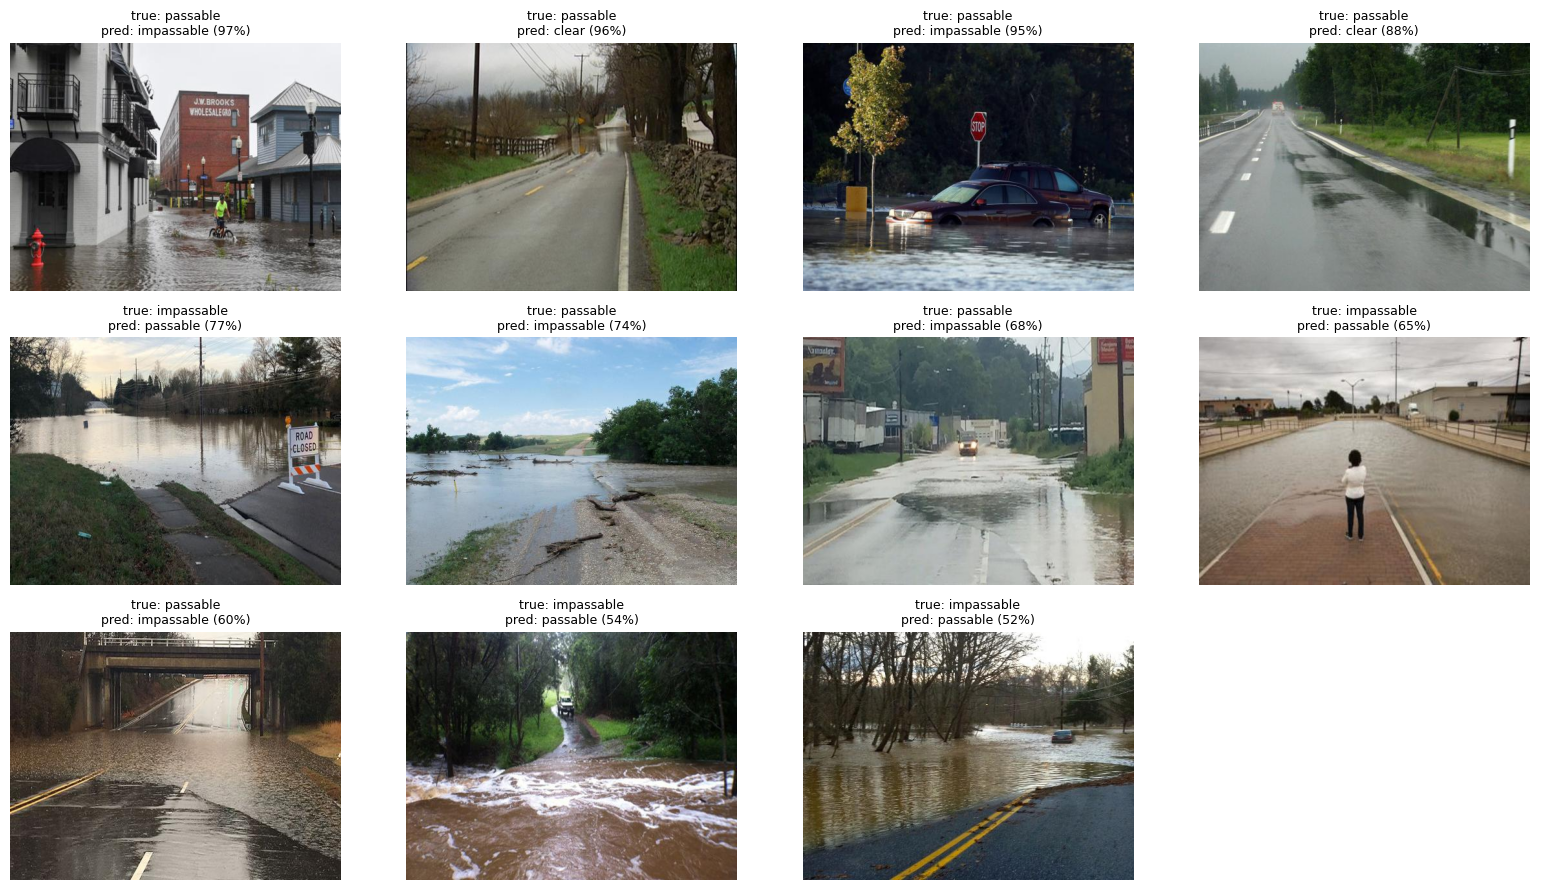

In [16]:
wrong = np.where(preds != ys)[0]
wrong = wrong[np.argsort(-probs[wrong, preds[wrong]])][:12]   # most confident mistakes first
fig, axes = plt.subplots(3, 4, figsize=(16, 9))
for ax in axes.ravel(): ax.axis('off')
for ax, i in zip(axes.ravel(), wrong):
    ax.imshow(Image.open(val_df.path[i]).convert('RGB'))
    ax.set_title(f'true: {CLASSES[ys[i]]}\npred: {CLASSES[preds[i]]} ({probs[i, preds[i]]:.0%})', fontsize=9)
plt.tight_layout(); plt.show()

In [12]:
wrong_all = np.where(preds != ys)[0]
errors = pd.DataFrame({
    'name': val_df.name.values[wrong_all],
    'true': [CLASSES[ys[i]] for i in wrong_all],
    'predicted': [CLASSES[preds[i]] for i in wrong_all],
    'confidence': probs[wrong_all, preds[wrong_all]].round(2),
}).sort_values('confidence', ascending=False)
display(errors)
errors.to_csv(OUT_DIR / 'val_errors_v1.csv', index=False)

,name,true,predicted,confidence
5,image_44.jpg,passable,impassable,1.00
6,image_57.jpg,passable,impassable,0.98
8,image_353.jpg,impassable,passable,0.98
10,image_379.jpg,impassable,passable,0.92
7,image_332.jpg,impassable,passable,0.84
3,image_308.jpg,passable,impassable,0.80
4,image_391.jpg,passable,impassable,0.77
1,image_267.jpg,passable,clear,0.66
2,image_301.jpg,passable,clear,0.62
9,image_366.jpg,impassable,passable,0.60
